In [1]:
from helper_utils import *
import torch
import matplotlib.pyplot as plt

In [2]:

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

torch.set_default_device(device)
print(f"Using device = {torch.get_default_device()}")

Using device = mps:0


<a name="1"></a>
# 1. Data Pre-Processing

# 1.1 Data Cleaning

The first step is to define and clean our data. Initially, we need to convert Unicode to plain ASCII to limit the RNN input layers.

This is accomplished by converting Unicode strings to ASCII and allowing only a small set of allowed characters.

In [3]:
print (f"converting 'Ślusàrski' to {unicodeToAscii('Ślusàrski')}")

converting 'Ślusàrski' to Slusarski


## 1.2 Turning Names into Tensors

Now that we have all the names organized, we need to turn them into Tensors to make any use of them.

To represent a single letter, we use a “one-hot vector” of size <1 x n_letters>. A one-hot vector is filled with 0s except for a 1 at index of the current letter, e.g. "b" = <0 1 0 0 0 ...>.

To make a word we join a bunch of those into a 2D matrix <line_length x 1 x n_letters>.

That extra 1 dimension is because PyTorch assumes everything is in batches - we’re just using a batch size of 1 here.

In [4]:
print (f"The letter 'a' becomes {lineToTensor('a')}") #notice that the first position in the tensor = 1
print (f"The name 'Ahn' becomes {lineToTensor('Ahn')}") #notice 'A' sets the 27th index to 1

The letter 'a' becomes tensor([[[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0.]]], device='mps:0')
The name 'Ahn' becomes tensor([[[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0

## 1.3 Load Data

In [5]:
category_lines, all_categories = load_data()
category_lines['Italian'][:5]

['Abandonato', 'Abatangelo', 'Abatantuono', 'Abate', 'Abategiovanni']

In [6]:
print(f"The letter 'a' becomes:\n{lineToTensor('a')} \nwith size = {lineToTensor('a').size()}") #notice that the first position in the tensor = 1

The letter 'a' becomes:
tensor([[[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0.]]], device='mps:0') 
with size = torch.Size([1, 1, 58])


In [7]:
print(f"The name 'Jones' becomes:\n{lineToTensor('Jones')}\nwith size = {lineToTensor('Jones').size()}")

The name 'Jones' becomes:
tensor([[[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0.]],

        [[0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0

# 2. Model

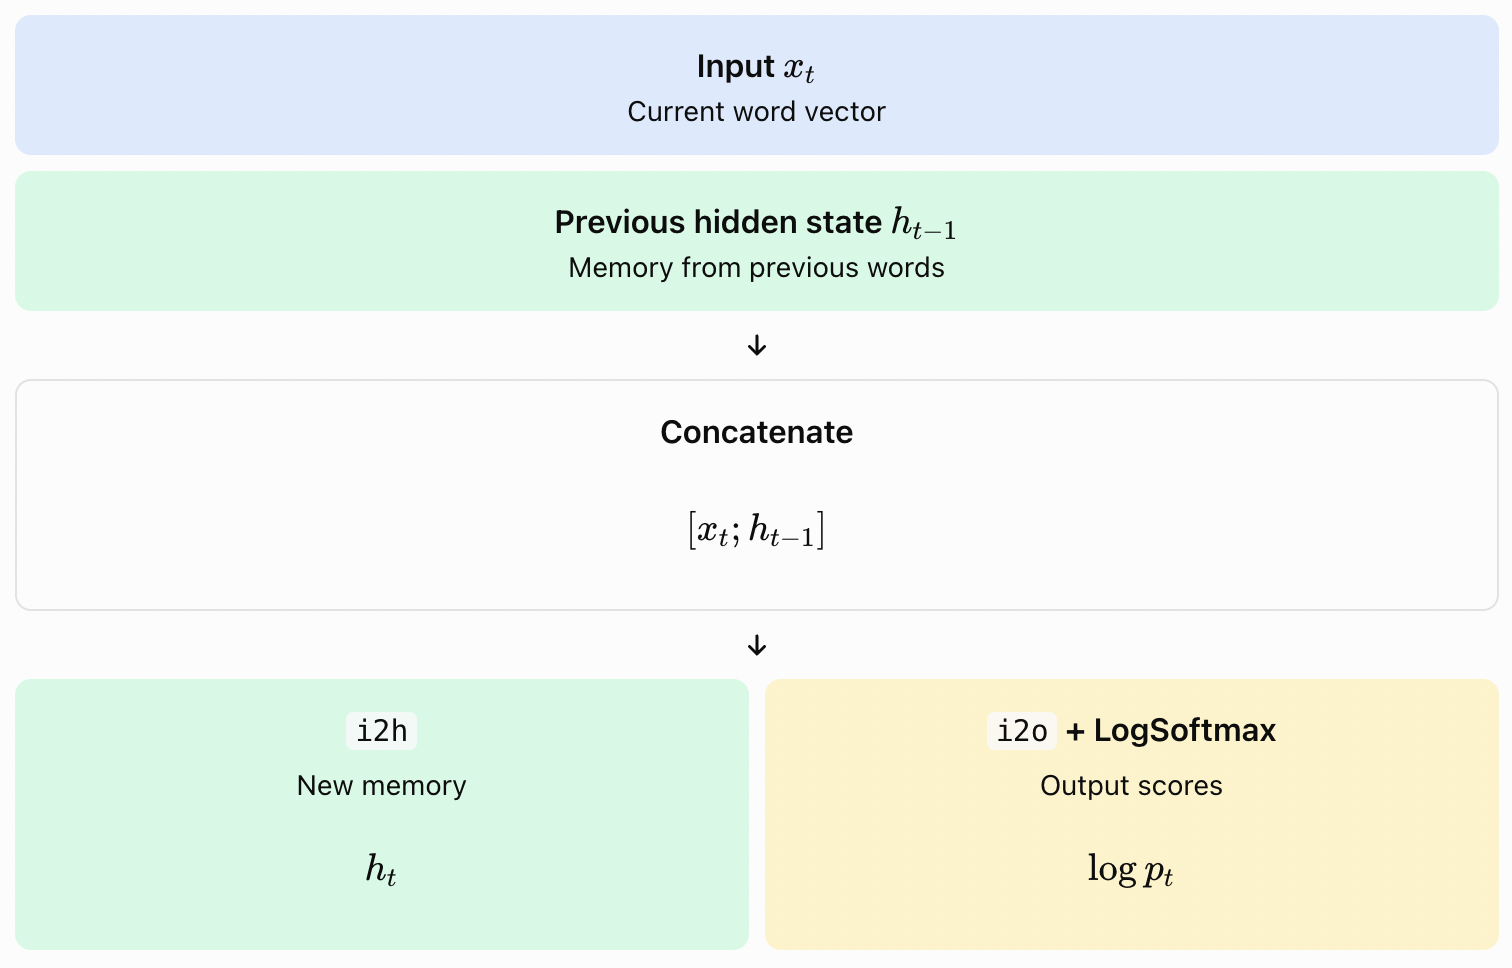

## 2.1 Model Definition

In [8]:

import torch
import torch.nn as nn

class RNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()

        self.hidden_size = hidden_size

        # Input + previous memory -> new memory
        self.i2h = nn.Linear(input_size + hidden_size, hidden_size)

        # Input + previous memory -> output scores
        self.i2o = nn.Linear(input_size + hidden_size, output_size)

        self.softmax = nn.LogSoftmax(dim=1)

    def forward(self, x, hidden):
        combined = torch.cat([x, hidden], dim=1)

        hidden = self.i2h(combined)
        output = self.softmax(self.i2o(combined))

        return output, hidden

    def init_hidden(self):
        return torch.zeros(1, self.hidden_size, device=device)


In [9]:
category_lines, all_categories = load_data()

In [10]:
n_categories = len(all_categories)
n_categories

18

## 2.2 Model Initialisation

In [11]:
n_hidden = 128
rnn = RNN(n_letters, n_hidden, n_categories).to(device)

## 2.2.1 Testing with one example

In [13]:
input_tensor = letterToTensor('A')
hidden_tensor = rnn.init_hidden()

output, next_hidden = rnn(input_tensor, hidden_tensor)

output.shape, next_hidden.shape

(torch.Size([1, 18]), torch.Size([1, 128]))

In [ ]:
input_tensor.size()

torch.Size([1, 1, 58])

In [15]:
input_tensor = lineToTensor('Albert')
hidden_tensor = rnn.init_hidden()

output, next_hidden = rnn(input_tensor[0], hidden_tensor)

output.shape, next_hidden.shape

(torch.Size([1, 18]), torch.Size([1, 128]))

In [16]:
def category_from_output(output):
    category_idx = torch.argmax(output).item()
    return all_categories[category_idx]


In [17]:
print(f"Predicted category for 'Albert' is {category_from_output(output)}")

Predicted category for 'Albert' is Irish


In [18]:
criterion = nn.NLLLoss()
learning_rate = 0.005
optimizer = torch.optim.SGD(rnn.parameters(), lr=learning_rate)

In [19]:
def train(line_tensor, category_tensor):
    hidden = rnn.init_hidden()

    rnn.zero_grad()

    for i in range(line_tensor.size()[0]):
        output, hidden = rnn(line_tensor[i], hidden)

    loss = criterion(output, category_tensor)
    loss.backward()

    optimizer.step()

    return output, loss.item()

In [20]:
current_loss = 0
all_losses = []

plot_steps, print_steps, n_iters = 1000, 100, 10000

100 2.8665 Holzakov / Portuguese ✗ (Russian)
200 2.9582 Salib / Korean ✗ (Arabic)
300 2.7938 Whyte / Scottish ✓
400 2.8904 Stablum / Scottish ✗ (Italian)
500 2.8528 Chang / Russian ✗ (Korean)
600 2.8714 Awkhadieff / Scottish ✗ (Russian)
700 2.8713 Pascal / Polish ✗ (French)
800 2.7888 Mcneil / Korean ✗ (Irish)
900 2.7163 Shakhnazarov / Russian ✓
1000 2.7779 Ventura / Arabic ✗ (Portuguese)
1100 2.8124 Cleirigh / Portuguese ✗ (Irish)
1200 2.8519 Whiteford / Arabic ✗ (English)
1300 2.8433 Panders / Portuguese ✗ (Dutch)
1400 2.8121 Duchamps / Greek ✗ (French)
1500 2.8469 Bai / Polish ✗ (Chinese)
1600 2.6125 Babikov / Russian ✓
1700 2.7864 Mclaughlin / Arabic ✗ (Scottish)
1800 2.7128 Schroeter / Arabic ✗ (German)
1900 2.8303 Walker / German ✗ (Scottish)
2000 2.7117 Nagasawa / Arabic ✗ (Japanese)
2100 2.3596 Sfakianos / Greek ✓
2200 2.7752 Ruadhan / Arabic ✗ (Irish)
2300 2.9639 Layton / Dutch ✗ (English)
2400 2.6703 Basurto / Portuguese ✓
2500 3.1778 Rhee / German ✗ (Korean)
2600 2.8483 Mars

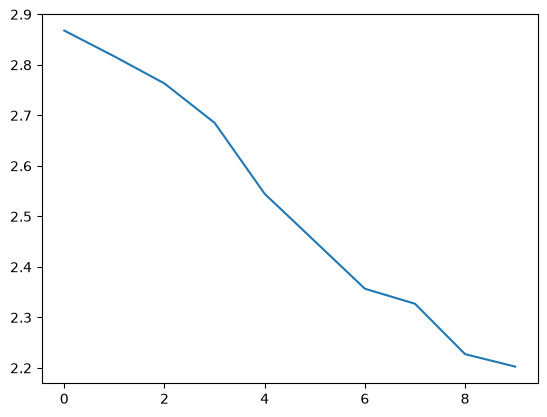

In [27]:
for i in range(n_iters):
    category, line, category_tensor, line_tensor = random_training_example(category_lines, all_categories)
    output, loss = train(line_tensor, category_tensor)
    current_loss += loss

    # Print iter number, loss, name and guess
    if (i + 1) % print_steps == 0:
        guess = category_from_output(output)
        correct = '✓' if guess == category else f'✗ ({category})'
        print(f'{i + 1} {loss:.4f} {line} / {guess} {correct}')

    # Add current loss avg to list of losses
    if (i + 1) % plot_steps == 0:
        all_losses.append(current_loss / plot_steps)
        current_loss = 0

plt.figure()
plt.plot(all_losses)
plt.show()


In [28]:
def predict(input_line):
    with torch.no_grad():
        line_tensor = lineToTensor(input_line)

        hidden = rnn.init_hidden()

        for i in range(line_tensor.size()[0]):
            output, hidden = rnn(line_tensor[i], hidden)

        guess = category_from_output(output)
        return guess

In [31]:
predict('Bian')

'Chinese'